# Orthonormal Wavefunctions

In this activity, students will explore the properties of quantum mechanical wavefunctions. Specifically, students will explore the properties of completeness and orthonormality, while also developing cyberinfrastructure (CI) skills such as integration using scipy and plotting with matplotlib.

## Lesson Information

### Learning Objectives (LOs)

#### Cyberinfrastructure LOs

By the end of this lesson, students will be able to perform the following cyberinfrastructure (CI) tasks:
1. Write user-defined functions
2. Use `np.isclose()` to deal with floating point precision issues
3. Create plots with multiple subplots using `plt.subplots()`

#### Content LOs

By the end of this lesson, students will be able to:

1. Calculate the inner product of two functions
2. Use the inner product to determine if functions in a set are orthonormal
3. Normalize a set of orthoganal functions
4. Normalize a superposition wavefunction
5. Calculate the coefficients for a basis function in a superposition wavefunction
6. Interpret how the basis function coefficients and normalization constant scale a wavefunction

### Lesson Prerequisites

#### Cyberinfrastructure Prereq's

Before beginning this lesson, students are expected to have the following CI skills:

1. Introduction to Python Programming
   * [Introduction to Programming for Molecular Scientists](https://act-cms.molssi.org/portal/lessons/foundational-intro-python/)
2. Basic understanding of numpy arrays, lambda expressions, plotting in matplotlib
   * [Introduction to Probability Distributions](https://act-cms.molssi.org/portal/lessons/introduction-to-probability-distributions/)


#### Content Prereq's

Before beginning this lesson, students are expected to be familiar with the following content topics (e.g., in a lecture the class before):
1. The quantum mechanical state postulate and properties of wavefunctions
2. Quantum mechanical operators and eigenvalue equations
3. Basic ideas of orthonormality and completeness
4. Basic ideas related to normalization of probability distributions
5. Dirac notation is not necessary, but is helpful (background information is provided)

## Import Relevant Libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

# Background Information

The information here serves as a quick reference for concepts that we've covered in lecture. This activity will enable you to see how the concepts from lecture apply to a specific set of functions. 

### The State Postulate

The state of a quantum mechanical system is described by a wavefunction, $\psi(x)$. The modulus square of the wavefunction is a probability distribution function, $P(x) = \psi^*(x)\psi(x)$, which tells us the probability of finding the quantum system/particle at a particular position. (Remember, we can't know the position exactly according to the Heisenberg uncertainty principle.)

We can get the probability that the quantum system exists in some region of space if we integrate the probability distribution over that region of space. If we intergrate a normalized probability distribution function over *all* space, we get the total probability that the quantum system exists *somewhere* in space, and the total probability has to be 1=100% in order to make physical sense, which means the wavefunction must be normalized, $1 =\int_{-\infty}^{\infty} P(x) dx =  \int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx $.

If the function is not normalized to begin with, then you will need to find the normalization constant that will ensure the total probability is equal to 100%. If the wavefunction, $\psi(x)$, is not normalized, then the expression $1 =\int_{-\infty}^{\infty} P(x) dx $ looks a little different. The normalized wavefunction is represented by $N \psi(x)$, where $N = \frac{1}{\sqrt{\int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx}}$.

The total probability is then given by:

$1 =\int_{-\infty}^{\infty} P(x) dx = N^2 \int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx =\left(\frac{1}{\sqrt{\int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx}}\right)^2 {\int_{-\infty}^{\infty}\psi^*(x)\psi(x)dx }= \frac{\int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx }{\int_{-\infty}^{\infty}\psi^*(x)\psi(x)dx }$.

### Quantum Operators and Eigenvalue Equations

The Time Independent Schrodinger Equation (TISE) is an eigenvalue equation. An eigenvalue equation is when an operator operates on a function to return a scalar value (the eigenvalue) times that same function (the eigenfunction).

$\hat O f_n(x) = o_n f_n(x)$

Quantum mechanical operators are linear operators, which means that the result of operation is consistent under scalar multiplication or addition (i.e., distribution).

$\hat O (af(x) + bg(x)) = a\hat O f(x) +b\hat O g(x)$

Certain linear operators, such as the Hermitian operators that represent measured quantities in quantum mechanics, can have multiple eigenfunctions, and each eigenfunction has an eigenvalue that corresponds to it. In other words, each operator has a *set* of eigenfunctions with corresponding eigenvalues. When two eigenfunctions have the same eigenvalue, they are called *degenerate* (e.g., the eigenfunctions do not generate a new or different eigenvalue).


In the TISE, the operator is the Hamiltonian operator (the sum of kinetic and potential energy operators), the eigenfunctions are the stationary state wavefunctions (i.e., the non-time-dependent states), and the eigenvalues are the total energy values that correspond to each stationary state the system could be in.

$\hat H \psi_n(x) = E_n \psi_n(x)$


### Orthonormality and Completeness

The eigenfunctions of quantum mechanical operators form a **complete orthonormal basis**.
* The eigenfunctions of quantum mechanical operators are *orthonormal*.
* The eigenfunctions of quantum mechanical operators form a *complete basis*.

A complete, orthonormal basis is something you are already familiar with! 

The unit vectors in real 3D space constitute a complete, orthonormal basis!

$e_i=\begin{pmatrix} 1 \\ 0 \\ 0 \end{pmatrix}$, $e_j=\begin{pmatrix} 0 \\ 1 \\ 0 \end{pmatrix}$
, $e_k=\begin{pmatrix} 0 \\ 0 \\ 1 \end{pmatrix}$

This is because they have a length of 1 and are perpendicular to one another, and any vector in 3D space can be described using the three unit vectors.

#### Dirac Notation (Bra-ket notation)
Dirac notation is a shorthand that makes it straightforward to show and make use of the properties of orthonormality and completeness.

A *ket* $|n\rangle$ refers to
* Discrete: a column vector $n=\begin{pmatrix} n_1 \\ .\\.\\. \\ n_N \end{pmatrix}$
* Continuous: a function $f_n(x)$

A *bra* $\langle n|$ refers to
* Discrete: the complex conjugate of $n=\begin{pmatrix} n_1 \\ .\\.\\. \\ n_N \end{pmatrix}$, which is:   $n^*=\begin{pmatrix} n_1^* \ ... \ n_N^* \end{pmatrix}$
* Continuous: the complex conjugate of the function $f_n(x)$: $f_n^*(x)$

Remember, to get the complex conjugate, replace any imaginary number $i$ with $-i$. 
So, if you have a complex number $z=a+ib$, its complex conjugate is $z^*=a+(-i)b=a-ib$. Here, since we are dealing with real functions, we don't really need to worry about the complext conjugate, but it's better to treat it properly so we know how to handle it when our functions are complex (not real).


#### **Orthonormality**
A set of functions (or vectors) is orthonormal when they are *orthogonal* to one another and *normalized*. These properties are based on the dot product between two vectors or functions in the set. The dot product is also called the scalar product or the *inner product*.

Inner Product:
* Discrete: $\langle n | m \rangle = n \cdot m = \begin{pmatrix} n_1^* \ ... \ n_N^* \end{pmatrix}\begin{pmatrix} m_1 \\ .\\.\\. \\ m_N \end{pmatrix}$
* Continuous: $\langle n | m \rangle = \int_{-\infty}^{\infty} f_n^*(x)f_m(x) dx$

Conditions for orthonormality:
* Two functions or vectors are *orthogonal* when their inner product is zero.
* A function or vector is *normalized* when the inner product of the function or vector with itself is 1.

The Kronecker delta function provides a shorthand for the result of taking the inner product of functions or vectors in an orthonormal set:

$\langle n | m \rangle = \delta_{nm} = \Bigg\{\begin{matrix} 0, n\neq m \\ 1, n=m \end{matrix}$


#### **Completeness**
Eigenfunctions of quantum mechanical operators form a complete set (of functions that serve as a basis for the space).
* Any well-behaved, square-integrable function, $\psi(x)$, can be expanded in a complete basis
* Any well-behaved, square-integrable function, $\psi(x)$, can be expanded in the eigenfunctions, $\phi(x)$, of any quantum mechanical operator defined in the same space.

# Exploring a Complete Orthonormal Set of Functions!
In this activity, we will demonstrate the properties of wavefunctions described in the background information using a complete set of orthonormal functions, $f_a(x) = \sin(ax)$, where we will assume that $a$ is an integer: $a\in Integers$ and that the relevant region of space is the interval $0\le x \le 2\pi$.

## Define the Set of Functions

We can define the functions as a user-defined function called `sin(x,a)` with arguments `x` for the spatial variable and `a` for the integer we multiply times `x`. You can use the built in `np.sin()` function in your definition.

In [4]:
## Write the definition of the functions here
def sin(x,a):
  return np.sin(a*x)

Next define a function `conj_func_product()` for the product of the complex conjugate and the non-conjugate function (which would be the modulus square if it's for one function in the set) and `inner_product()` for the inner product of the two functions. 

Use `np.conjugate()` and `scipy.integrate.quad()` to write your definitions. Remember when using `scipy.integrate.quad()` that you have to use a `lamba` expression when your function has multiple arguments.

In [64]:
## Define the modulus square of those functions
def conj_func_product(x, a1, a2):
  return np.conjugate(sin(x,a1)) * sin(x,a2)

## Define the inner product of those functions
def inner_product(product_function, a1, a2):
   return scipy.integrate.quad(lambda x: product_function(x, a1, a2), 0, 2*np.pi)[0]

## Visualize the Functions by Plotting Them

Let's see what the functions that you've just defined look like! 

In [65]:
## Create an array to define the x-axis values from 0 to 2pi
x_axis = np.linspace(0,2*np.pi,4000)

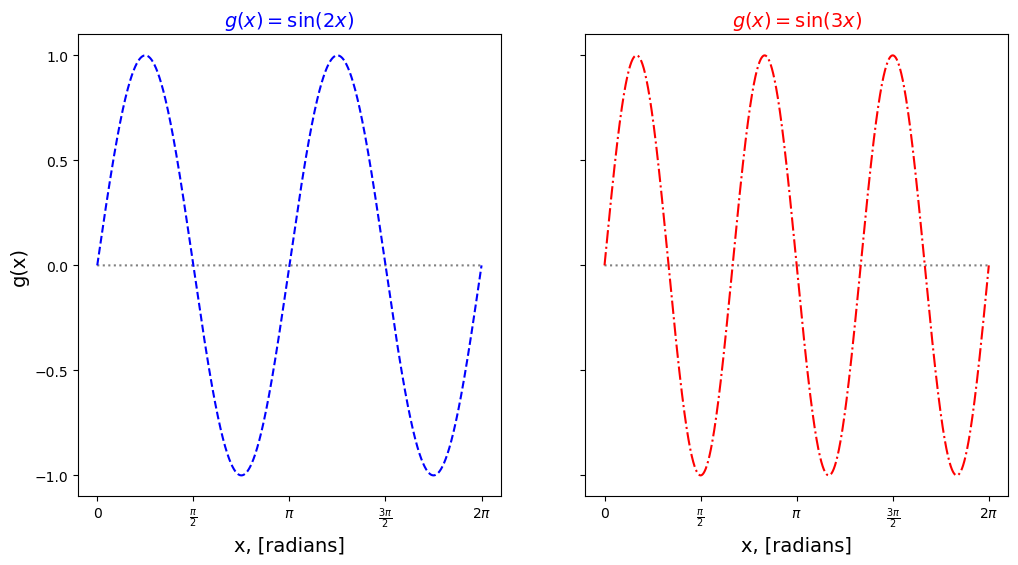

In [66]:
## Create a plot of a couple functions here
fig, ax = plt.subplots(ncols=2,  figsize=(12,6), sharex=True, sharey=True)

## Upper Left Subplot
ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, sin(x_axis,2), linestyle = "--", color="blue")

## Upper Right Subplot
ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, sin(x_axis,3), linestyle = "-.", color="red")

## Labels and Formatting for Subplots
ax[0].set_title(r'$g(x) = \sin(2x)$', fontsize="14", color="blue")
ax[1].set_title(r'$g(x) = \sin(3x)$', fontsize="14", color="red")

## Only need to set xticks and yticks once because all axes share x and y axis values 
## due to sharex=True and sharey=True setting
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[1].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],
                   labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")


plt.show()

Great! We can see that we've defined some functions that we are able to plot. But what does that tell us about orthonormality? Not much.

So let's see what the inner product tells us...

## Calculate the Inner Product to Demonstrate Orthogonality

Here we will define a 5x5 array of zeros to see what the inner product would be between each of the first five functions in the set, for $a=1$ through $a=5$.

In [74]:
# Define an np.zeros() array
rounded_inner_product = np.zeros(shape=(5,5))
print(rounded_inner_product)

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


Next we can create a nested for loop to iterate over each of the $a$ values in each function. 

Use iteration variable `i` to refer to the value of $a$ in the first function, and `j` to refer to the value of $a$ in the second function.

We will also (re-)introduce the *formatted print* option, which can be nice when you want to print multiple variables on the same line.
`print(f"string to print {variable1} and more string {variable2}")`

In [68]:
for i in range(1,6,1):
  for j in range(1,6,1):
      print(f"i = {i}, j = {j}")
      print("inner product = ",inner_product(conj_func_product,i,j))
      rounded_inner_product[i-1,j-1] = round(inner_product(conj_func_product,i,j),10)
print(rounded_inner_product)

i = 1, j = 1
inner product =  3.141592653589793
i = 1, j = 2
inner product =  5.915234055980641e-17
i = 1, j = 3
inner product =  6.967844571128478e-16
i = 1, j = 4
inner product =  -9.967226378654006e-17
i = 1, j = 5
inner product =  -2.2634253568627697e-16
i = 2, j = 1
inner product =  5.915234055980641e-17
i = 2, j = 2
inner product =  3.141592653589793
i = 2, j = 3
inner product =  2.104602201189698e-17
i = 2, j = 4
inner product =  5.546749666222591e-17
i = 2, j = 5
inner product =  -3.1888486090506e-16
i = 3, j = 1
inner product =  6.967844571128478e-16
i = 3, j = 2
inner product =  2.104602201189698e-17
i = 3, j = 3
inner product =  3.141592653589793
i = 3, j = 4
inner product =  2.79433832044808e-16
i = 3, j = 5
inner product =  -2.38666011564464e-17
i = 4, j = 1
inner product =  -9.967226378654006e-17
i = 4, j = 2
inner product =  5.546749666222591e-17
i = 4, j = 3
inner product =  2.79433832044808e-16
i = 4, j = 4
inner product =  3.141592653589793
i = 4, j = 5
inner product 

<h2 style="color:Purple;">Self Check 1</h2>

1. What do you notice about the inner product when the multiplicative factors in `sin(a*x)` are equal, i.e., when `a1 = a2`?
2. What do you notice about the inner product when they're not equal?
3. What impact does rounding have on the values, and why?

<h2 style="color:Purple;">Provide your answer in the Markdown cell below:</h2>

1. 

2. 

3. 

### Follow up to Self Check 1: 
The issue with the really small values calculated for the inner product of different sine functions in the set is caused by issues of [floating point precision](https://numpy.org/doc/stable/user/basics.types.html#floating-point-precision). 
If you want to deal with floating point precision so that the values in the array are actually zero, one way to do so is to use the `np.isclose()` function. 

Let's clean up the for loop using the `np.isclose()` function:

In [163]:
for i in range(1,6,1):
  for j in range(1,6,1):
      ## Set the comparison value as zero, and the tolerance to 1e-10
      if np.isclose(inner_product(conj_func_product,i,j),0,rtol=1e-10):
          rounded_inner_product[i-1,j-1] = 0
      else:
          rounded_inner_product[i-1,j-1] = inner_product(conj_func_product,i,j)
print(rounded_inner_product)

[[3.14159265 0.         0.         0.         0.        ]
 [0.         3.14159265 0.         0.         0.        ]
 [0.         0.         3.14159265 0.         0.        ]
 [0.         0.         0.         3.14159265 0.        ]
 [0.         0.         0.         0.         3.14159265]]


Is it ok to do that though? How do we know that those small numbers aren't actually important and are just due to precision rounding? Well, we can't know because the error in the integration is actually larger than the calculated value.

In [78]:
print(scipy.integrate.quad(conj_func_product, 0, 2*np.pi, args=(1,2)))

(5.915234055980641e-17, 2.9194772684440484e-14)


We can see that the error in the integration used in the `inner_product` calculation is on the order of $10^{-14}$, which is a few orders of magnitude greater than the integral value itself on the order of $10^{-17}$ ish. This means that we can round the value to within the error, so the 14th decimal place is really as small as we can go...basically, within error, the value calculated is zero. 

## Visualize the Inner Product by Plotting the Product of Complex Conjugate times Function

You can visualize the inner product of two functions by plotting complex conjugate of the first function times the second function and looking at what the integral of the product would be by filling to the axis. 

First, let's see how to plot that product for a couple combinations of functions by plotting the functions alongside their   product.

Note here that we are now plotting things with multiple rows! We can access the subplots in the different positions using `ax[row,column]`.

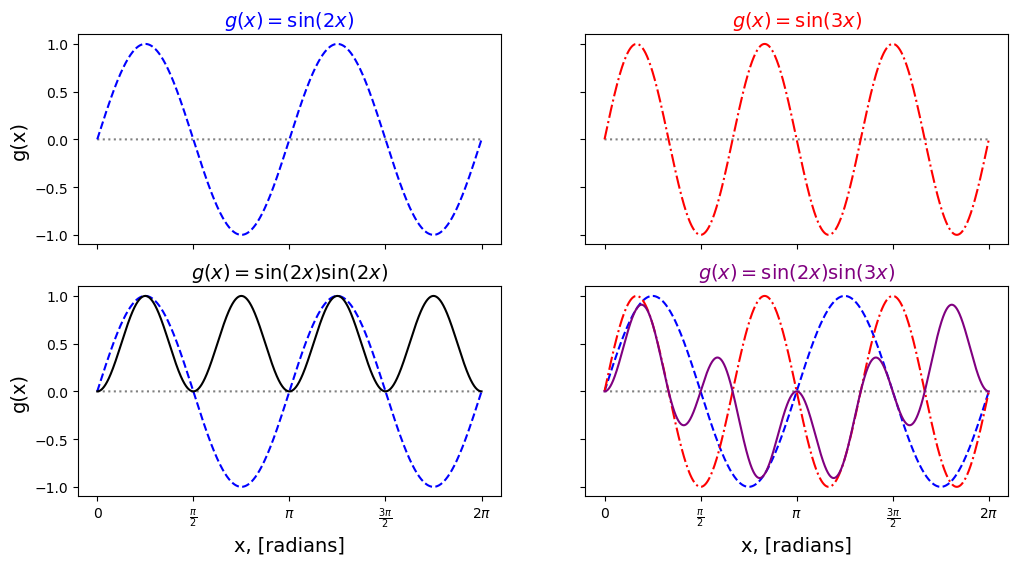

In [70]:
## Plot a few of the functions and their modulus squares
fig, ax = plt.subplots(nrows=2, ncols=2,  figsize=(12,6), sharex=True, sharey=True)

## Upper Left Subplot
ax[0,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,0].plot(x_axis, sin(x_axis,2), linestyle = "--", color="blue")

## Upper Right Subplot
ax[0,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,1].plot(x_axis, sin(x_axis,3), linestyle = "-.", color="red")

## Lower Left Subplot
ax[1,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,0].plot(x_axis, sin(x_axis,2), linestyle = "--", color="blue")
ax[1,0].plot(x_axis, conj_func_product(x_axis,2,2), linestyle = "-", color="black")

## Lower Right Subplot
ax[1,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,1].plot(x_axis, sin(x_axis,2), linestyle = "--", color="blue")
ax[1,1].plot(x_axis, sin(x_axis,3), linestyle = "-.", color="red")
ax[1,1].plot(x_axis, conj_func_product(x_axis,2,3), linestyle = "-", color="purple")

## Labels and Formatting for Subplots
ax[0,0].set_title(r'$g(x) = \sin(2x)$', fontsize="14", color="blue")
ax[0,1].set_title(r'$g(x) = \sin(3x)$', fontsize="14", color="red")
ax[1,0].set_title(r'$g(x) = \sin(2x)\sin(2x)$', fontsize="14", color="black")
ax[1,1].set_title(r'$g(x) = \sin(2x)\sin(3x)$', fontsize="14", color="purple")

## Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0,0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[1,0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))


ax[0,0].set_ylabel("g(x)", fontsize="14")
ax[1,0].set_ylabel("g(x)", fontsize="14")

ax[1,1].set_xlabel("x, [radians]", fontsize="14")
ax[1,0].set_xlabel("x, [radians]", fontsize="14")


plt.show()

<h2 style="color:Purple;">Self Check 2</h2>

Now you can try plotting the product functions in the bottom row of the plot above, but fill to the axis in order to signify integration as the total area under the curve. Remember, the area under the axis is negative, so it cancels with any area above the axis. 

1. What do you notice about the area under the curve for $g(x) = \sin(2x)\sin(2x)$?
   
2. What do you notice about the area under the curve for $g(x) = \sin(2x)\sin(3x)$?

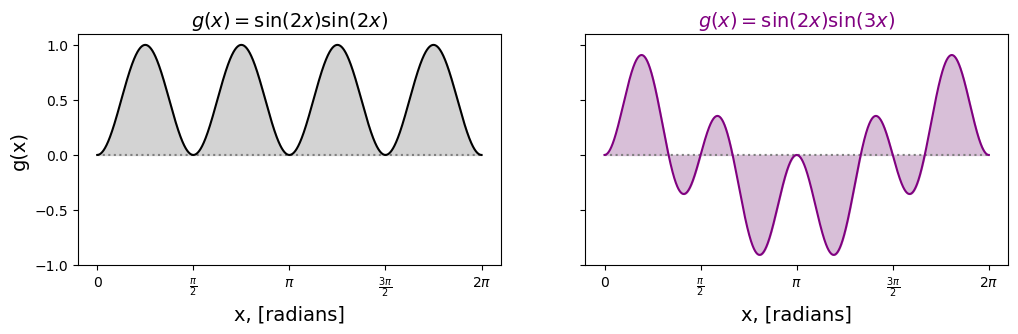

In [73]:
## Plot the conj_func_product() for the functions filled to the axis to signify integration
fig, ax = plt.subplots(ncols=2,  figsize=(12,3), sharex=True, sharey=True)

ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, conj_func_product(x_axis,2,2), linestyle = "-", color="black")
ax[0].fill_between(x_axis, conj_func_product(x_axis,2,2), color="lightgray")

ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, conj_func_product(x_axis,2,3), linestyle = "-", color="purple")
ax[1].fill_between(x_axis, conj_func_product(x_axis,2,3), color="thistle")

# Labels and Formatting for Subplots
ax[0].set_title(r'$g(x) = \sin(2x)\sin(2x)$', fontsize="14", color="black")
ax[1].set_title(r'$g(x) = \sin(2x)\sin(3x)$', fontsize="14", color="purple")

# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")


plt.show()

<h2 style="color:Purple;">Provide your answer in the Markdown cell below:</h2>

1. 

2. 


## Calculate the Inner Product to Normalize the Function Set


Based on both the calculations and the plots, we can see that the different functions in the set are orthogonal, that is, their inner product is zero. 

But you may have noticed that there's an issue with the inner product, because the inner product of a function in this set with itself is not equal to 1. In order to ensure this is the case, we need to make sure the set of functions is normalized.

Based on the values reported in `rounded_inner_product`, you may already note that the normalization constant will be $\frac{1}{\pi}$.

But we can also calculate the normalization constant using $N = \frac{1}{\sqrt{\int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx}}$. Note that it's the same value regardless of which of the same functions we are taking the inner product of - all the diagonal values of `norm_const` are the same.

<h2 style="color:Purple;">Self Check 3</h2>

Write a for loop to determine the normalization constant for the first five functions in the set and show that it is the same regardless of which function in the set is used to calculate it. Also confirm for yourself that the value you calculate is $N=\frac{1}{\sqrt{\pi}}$.

In [91]:
## Write your for loop here
norm_const = np.zeros(shape=(5,5))
for i in range(1,6,1):
  for j in range(1,6,1):
      if np.isclose(inner_product(conj_func_product,i,j),0,rtol=1e-10):
          norm_const[i-1,j-1] = 0
      else:
          norm_const[i-1,j-1] = np.sqrt(1 / inner_product(conj_func_product,i,j))
print(norm_const)

[[0.56418958 0.         0.         0.         0.        ]
 [0.         0.56418958 0.         0.         0.        ]
 [0.         0.         0.56418958 0.         0.        ]
 [0.         0.         0.         0.56418958 0.        ]
 [0.         0.         0.         0.         0.56418958]]


In [161]:
## Verify the value of the normalization constant here
norm_const_calc = 1/np.sqrt(np.pi)
print(norm_const_calc)
norm_const_calc = np.pi**(-1/2)
print(norm_const_calc)

0.5641895835477563
0.5641895835477563


You should find that the values are the same, so it doesn't really matter which one you use in your code.

## Define the Set of Normalized Functions

Now we can use the normalization constant to define the normalized set of functions, $f_a(x) = \frac{1}{\sqrt{\pi}}\sin(ax)$, over the interval $0\le x\le 2\pi$.

In [92]:
## Define the normalized set of functions using the normalization constant
def norm_sin(x,a):
  return (np.pi)**(-1/2) * np.sin(a*x)

def norm_conj_func_product(x, a1, a2):
  return np.conjugate(norm_sin(x,a1)) * norm_sin(x,a2)

## Visualizing the normalized inner products

Now we can go ahead and plot the normalized functions and their products to see how the inner product will be impacted by normalization. Use the plots from just before Self Check 2, and also the plot that you made in Self Check 2, to plot the functions and to visualize with filling to the axis what the inner product would be. 

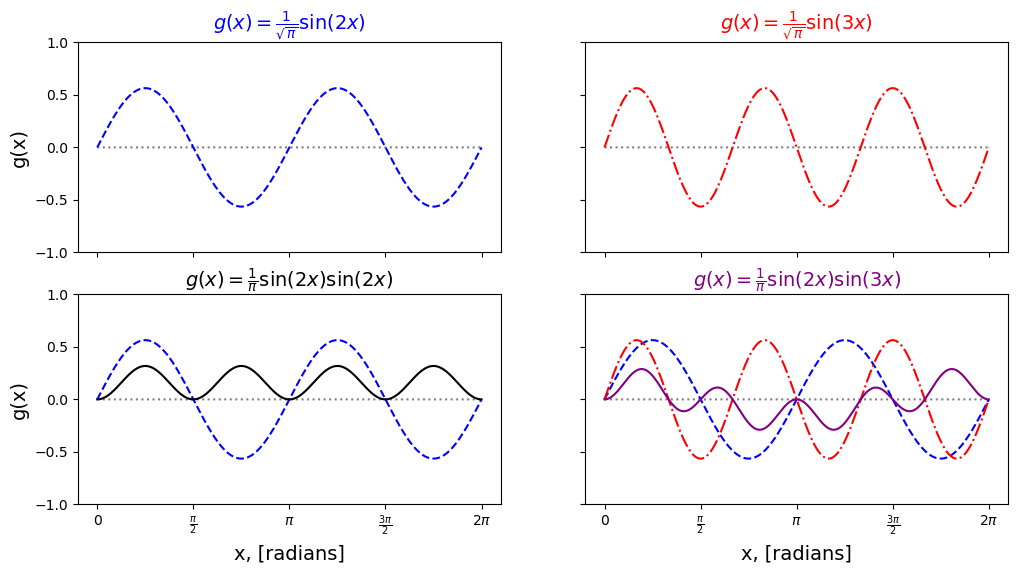

In [100]:
## Plot a few of the normalized functions and their products
fig, ax = plt.subplots(nrows=2, ncols=2,  figsize=(12,6), sharex=True, sharey=True)

## Upper Left Subplot
ax[0,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,0].plot(x_axis, norm_sin(x_axis,2), linestyle = "--", color="blue")

## Upper Right Subplot
ax[0,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,1].plot(x_axis, norm_sin(x_axis,3), linestyle = "-.", color="red")

## Lower Left Subplot
ax[1,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,0].plot(x_axis, norm_sin(x_axis,2), linestyle = "--", color="blue")
ax[1,0].plot(x_axis, norm_conj_func_product(x_axis,2,2), linestyle = "-", color="black")

## Lower Right Subplot
ax[1,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,1].plot(x_axis, norm_sin(x_axis,2), linestyle = "--", color="blue")
ax[1,1].plot(x_axis, norm_sin(x_axis,3), linestyle = "-.", color="red")
ax[1,1].plot(x_axis, norm_conj_func_product(x_axis,2,3), linestyle = "-", color="purple")

## Labels and Formatting for Subplots
ax[0,0].set_title(r'$g(x) = \frac{1}{\sqrt{\pi}} \sin(2x)$', fontsize="14", color="blue")
ax[0,1].set_title(r'$g(x) = \frac{1}{\sqrt{\pi}} \sin(3x)$', fontsize="14", color="red")
ax[1,0].set_title(r'$g(x) = \frac{1}{\pi} \sin(2x) \sin(2x)$', fontsize="14", color="black")
ax[1,1].set_title(r'$g(x) = \frac{1}{\pi} \sin(2x)\sin(3x)$', fontsize="14", color="purple")

## Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0,0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[1,0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))


ax[0,0].set_ylabel("g(x)", fontsize="14")
ax[1,0].set_ylabel("g(x)", fontsize="14")

ax[1,1].set_xlabel("x, [radians]", fontsize="14")
ax[1,0].set_xlabel("x, [radians]", fontsize="14")


plt.show()

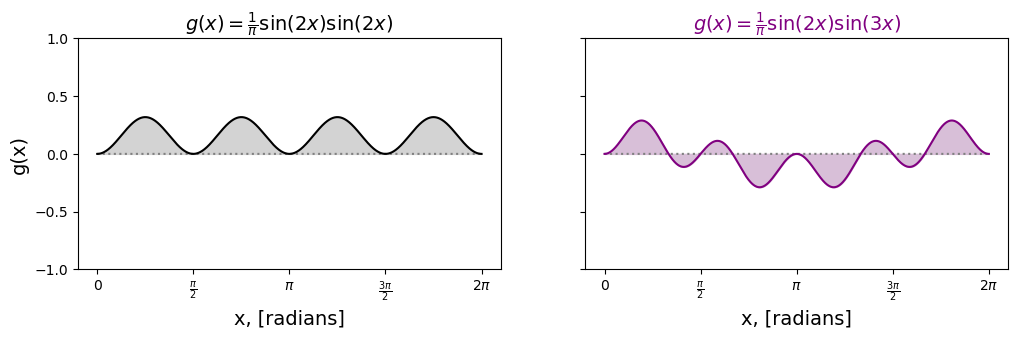

In [101]:
## Plot the products will filling to the axis to represent integration
fig, ax = plt.subplots(ncols=2,  figsize=(12,3), sharex=True, sharey=True)

ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, norm_conj_func_product(x_axis,2,2), linestyle = "-", color="black")
ax[0].fill_between(x_axis, norm_conj_func_product(x_axis,2,2), color="lightgray")

ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, norm_conj_func_product(x_axis,2,3), linestyle = "-", color="purple")
ax[1].fill_between(x_axis, norm_conj_func_product(x_axis,2,3), color="thistle")

# Labels and Formatting for Subplots
ax[0].set_title(r'$g(x) = \frac{1}{\pi} \sin(2x) \sin(2x)$', fontsize="14", color="black")
ax[1].set_title(r'$g(x) = \frac{1}{\pi} \sin(2x)\sin(3x)$', fontsize="14", color="purple")

# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")


plt.show()

<h2 style="color:Purple;">Self Check 4</h2>

Without calculating the inner product yet, what do the graphs tell you about the inner product of the normalized functions compared to the inner product of the non-normalized functions? 

<h2 style="color:Purple;">Provide your answer in the Markdown cell below:</h2>

Replace this text with your answer.

## Calculate the inner product of the functions to demonstrate orthonormality
We can verify that the inner product of the normalized function with itself is equal to 1.

In [103]:
## Create an array for the normalized inner product 
norm_ip = np.zeros(shape=(5,5))
for i in range(1,6,1):
  for j in range(1,6,1):
      if np.isclose(inner_product(norm_conj_func_product,i,j),0,rtol=1e-10):
          norm_ip[i-1,j-1] = 0
      else:
          norm_ip[i-1,j-1] = np.sqrt(1 / inner_product(norm_conj_func_product,i,j))
print(norm_ip)

[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


# Exploring a Complete, Orthonormal Set of Functions!

We have a set of orthonormal functions now, so they serve as a basis set for the space that the operator can operate on. Now we can see how to expand any function in terms of these basis functions, and how to determine if the function will serve as a physical quantum state by making sure the new function is also normalized.

Let's define two wavefunctions that are expanded in the set of complete, orthonormal sine functions we defined (over the interval $0\le x\le 2\pi$). One will be a good wavefunction where the coefficients make the function normalized, and one will be a bad wavefunction where the coefficients make the function not normalized. Let's refer to the normalized sine functions as $\phi_n(x)$. These $\phi_n(x)$ are like the normalized eigenfunctions of a quantum operator that form a complete basis set from which we can create any superposition wavefunction.

Good wavefunction: 

$\psi_{good}(x) = \frac{1}{2}\phi_1(x) - \frac{1}{2}\phi_2(x) +\frac{1}{\sqrt{2}}\phi_3(x)$

$\psi_{good}(x) = \frac{1}{2}\left(\frac{1}{\sqrt{\pi}}\sin(x)\right)- \frac{1}{2}\left(\frac{1}{\sqrt{\pi}}\sin(2x)\right)+ \frac{1}{\sqrt{2}}\left(\frac{1}{\sqrt{\pi}}\sin(3x)\right)$

Bad wavefunction: 

$\psi_{bad}(x) = \phi_1(x) - \phi_2(x) + \phi_3(x)$

$\psi_{bad}(x) = \frac{1}{\sqrt{\pi}}\sin(x)- \frac{1}{\sqrt{\pi}}\sin(2x)+ \frac{1}{\sqrt{\pi}}\sin(3x)$

In [115]:
## Good version of a wavefunction because coefficients are normalized
def good_wavefunction(x):
    return 1/2 * norm_sin(x,1) - 1/2 * norm_sin(x,2) + 1/np.sqrt(2) * norm_sin(x,3)

## Bad version of a wavefunction because coefficients are not normalized
def bad_wavefunction(x):
    return  norm_sin(x,1) - norm_sin(x,2) + norm_sin(x,3)

The coefficients for the superposition wavefunctions defined above are given by:

$c_n = \langle \phi_n | \psi \rangle$

The notation might seem a little strange, but we can demonstrate that that this is true!
(You can also derive that it is true algebraically if you like!)

In [116]:
def coefficient_1(x):
    return norm_sin(x,1) * good_wavefunction(x)
#c_1 = scipy.integrate.quad(coefficient_1, 0, 2*np.pi)[0]
c_1 = round(scipy.integrate.quad(coefficient_1, 0, 2*np.pi)[0],10)

print(c_1)

0.5


<h2 style="color:Purple;">Self Check 5</h2>

Now show that the coefficients for $\phi_2(x)$ and $\phi_3(x)$ are also equal to the inner product of the basis function with the total wavefunction.

In [120]:
## Define the coefficients here 
def coefficient_2(x):
    return norm_sin(x,2) * good_wavefunction(x)
c_2 = round(scipy.integrate.quad(coefficient_2, 0, 2*np.pi)[0],10)


def coefficient_3(x):
    return norm_sin(x,3) * good_wavefunction(x)
c_3 = round(scipy.integrate.quad(coefficient_3, 0, 2*np.pi)[0],10)

# Print the coefficients here 
print(c_2)
print(c_3)

-0.5
0.7071067812


We can also show the impact of these coefficients on the function. The "bad" wavefunction doesn't have coefficients that scale the basis eigenfunctions included in the superpostion. On the other hand, the "good" wavefunction *does* have coefficients that scale the basis eigenfunctions included in the superpostion, so the y-axis values for the good wavefunction are slightly smaller than those for the bad wavefunction.

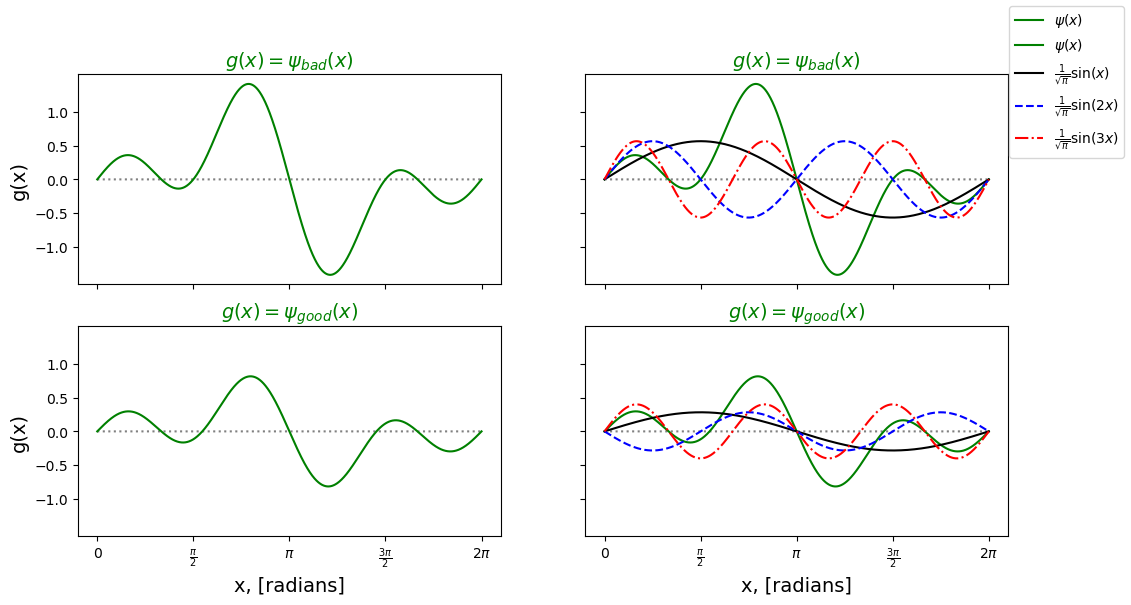

In [122]:
fig, ax = plt.subplots(nrows=2, ncols=2,  figsize=(12,6), sharex=True, sharey=True)

## Bad version of a wavefunction because coefficients are not normalized
ax[0,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,0].plot(x_axis, bad_wavefunction(x_axis), linestyle = "-", color="green", label = r'$\psi(x)$')

ax[0,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0,1].plot(x_axis, bad_wavefunction(x_axis), linestyle = "-", color="green", label = r'$\psi(x)$')
ax[0,1].plot(x_axis, norm_sin(x_axis,1), linestyle = "-", color="black", label = r'$\frac{1}{\sqrt{\pi}}\sin(x)$')
ax[0,1].plot(x_axis, norm_sin(x_axis,2), linestyle = "--", color="blue", label = r'$\frac{1}{\sqrt{\pi}}\sin(2x)$')
ax[0,1].plot(x_axis, norm_sin(x_axis,3), linestyle = "-.", color="red", label = r'$\frac{1}{\sqrt{\pi}}\sin(3x)$')

## Good version of a wavefunction because coefficients are normalized
ax[1,0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,0].plot(x_axis, good_wavefunction(x_axis), linestyle = "-", color="green")

ax[1,1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1,1].plot(x_axis, good_wavefunction(x_axis), linestyle = "-", color="green")
ax[1,1].plot(x_axis, 1/2 * norm_sin(x_axis,1), linestyle = "-", color="black")
ax[1,1].plot(x_axis, -1/2 * norm_sin(x_axis,2), linestyle = "--", color="blue")
ax[1,1].plot(x_axis, 1/np.sqrt(2) * norm_sin(x_axis,3), linestyle = "-.", color="red")

# Labels and Formatting for Subplots
ax[0,0].set_title(r'$g(x) = \psi_{bad}(x)$', fontsize="14", color="green")
ax[0,1].set_title(r'$g(x) = \psi_{bad}(x)$', fontsize="14", color="green")
ax[1,0].set_title(r'$g(x) = \psi_{good}(x)$', fontsize="14", color="green")
ax[1,1].set_title(r'$g(x) = \psi_{good}(x)$', fontsize="14", color="green")


# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0,0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0,0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0,0].set_ylabel("g(x)", fontsize="14")
ax[1,0].set_ylabel("g(x)", fontsize="14")

ax[1,0].set_xlabel("x, [radians]", fontsize="14")
ax[1,1].set_xlabel("x, [radians]", fontsize="14")

fig.legend()

plt.show()

<h2 style="color:Purple;">Self Check 6</h2>

Now make a plot to see what happens when we consider the modulus square of the good wavefunction. 

Make a subplots figure where the left graph shows the good wavefunction and the right graph shows the modulus square of the good wavefunction with filling to the axis to represent integration. Use the previous plotting code in this notebook to help!

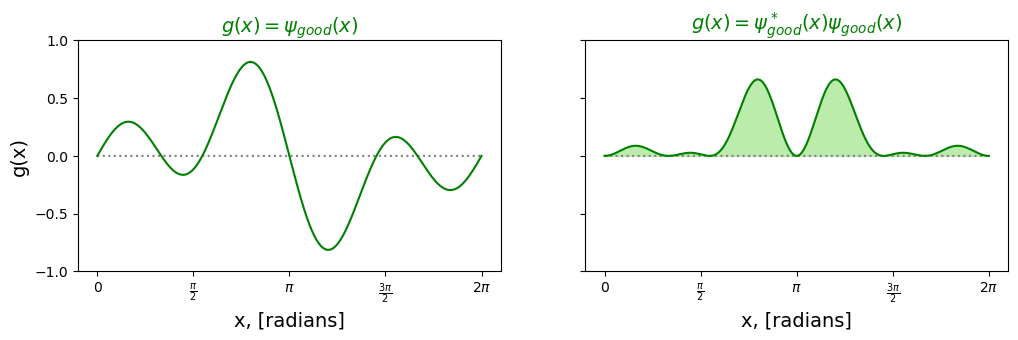

In [124]:
## Create your plot here
fig, ax = plt.subplots(ncols=2,  figsize=(12,3), sharex=True, sharey=True)

ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, good_wavefunction(x_axis), linestyle = "-", color="green")

ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, np.conjugate(good_wavefunction(x_axis)) * good_wavefunction(x_axis), linestyle = "-", color="green", label = r'$\psi(x)$')
ax[1].fill_between(x_axis, np.conjugate(good_wavefunction(x_axis)) * good_wavefunction(x_axis), color="xkcd:light sage")

# Labels and Formatting for Subplots
ax[0].set_title(r'$g(x) = \psi_{good}(x)$', fontsize="14", color="green")
ax[1].set_title(r'$g(x) = \psi_{good}^*(x)\psi_{good}(x)$', fontsize="14", color="green")


# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")

plt.show()

## Normalization of a Superposition Wavefunction
There's an extra step to normalizing a superposition wavefunction. Even though the eigenfunctions are normalized, we also have to make sure that the coefficients for the superposition wavefunction ensure that the total probability is 100%.

Let's define a function that will calculate the inner product of a superposition wavefunction with itself.

In [150]:
def total_prob(wavefunction):
    def mod_sq(x):
        return np.conjugate(wavefunction(x)) * wavefunction(x)
    return round(scipy.integrate.quad(mod_sq, 0, 2*np.pi)[0],10)

In [153]:
## Test total_prob for the good wavefunction
## Note that we don't need to include the (x) after good_wavefunction because that's added in the function itself
total_prob(good_wavefunction)

1.0

In [154]:
## Test total_prob for the bad wavefunction
total_prob(bad_wavefunction)

3.0

<h2 style="color:Purple;">Self Check 7</h2>

Now we know the total value of the inner product, so we can write a normalized wavefunction using $N = \frac{1}{\sqrt{\int_{-\infty}^{\infty} \psi^*(x)\psi(x)dx}}$! 

Go ahead and write an expression for the normalization constant for the bad wavefunction and call it `bad_wave_norm_const`.

In [158]:
## Write your expression here
bad_wave_norm_const = np.sqrt(1/total_prob(bad_wavefunction))

Now we can use that normalization constant to define a normalized bad wavefunction, and check to make sure that our normalization works by calculating the inner product for the wavefunction with itself. 

In [172]:
## Normalized version of the "bad" wavefunction
def norm_bad_wavefunction(x):
    return  bad_wave_norm_const * bad_wavefunction(x)

In [173]:
## Verify that the wavefunction is now normalized
total_prob(norm_bad_wavefunction)

1.0

Let's compare the bad wavefunction and the normalized version of it by plotting them side by side. Notice how the normalization constants scale the wavefunction.

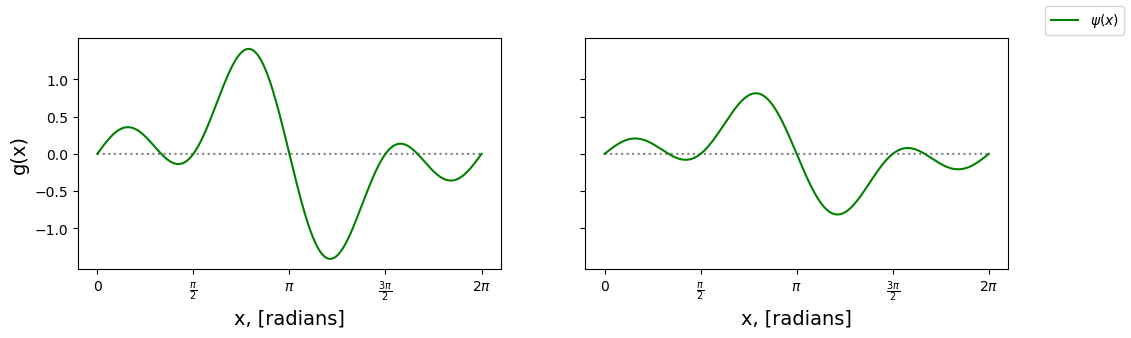

In [178]:
fig, ax = plt.subplots(ncols=2,  figsize=(12,3), sharex=True, sharey=True)

## Bad version of a bad wavefunction because coefficients are not normalized
ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, bad_wavefunction(x_axis), linestyle = "-", color="green")

## Normalized version of a bad wavefunction because coefficients have now been normalized
ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, norm_bad_wavefunction(x_axis), linestyle = "-", color="green", label = r'$\psi(x)$')

# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")

fig.legend()

plt.show()

Now let's plot the modulus square of the normalized bad wavefunction with filling to the axis to represent integration.

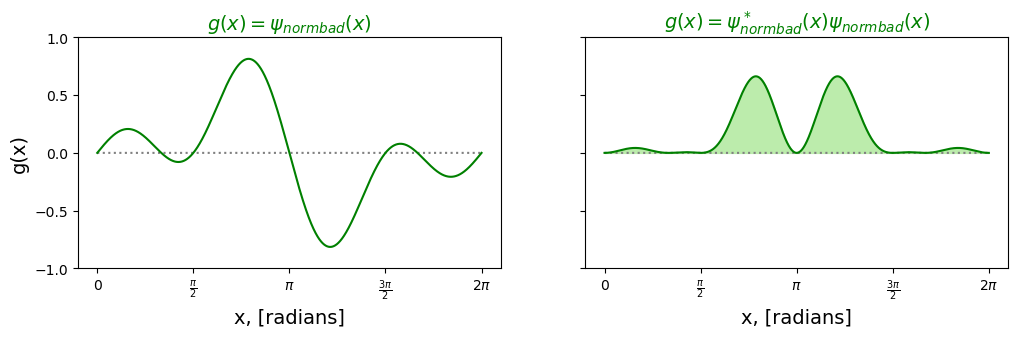

In [175]:
fig, ax = plt.subplots(ncols=2,  figsize=(12,3), sharex=True, sharey=True)

## Normalized version of a bad wavefunction 
ax[0].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[0].plot(x_axis, norm_bad_wavefunction(x_axis), linestyle = "-", color="green")

## Modulus square of the normalized bad wavefunction 
ax[1].plot(x_axis, np.zeros(len(x_axis)), linestyle = ":", color="gray")
ax[1].plot(x_axis, np.conjugate(norm_bad_wavefunction(x_axis)) * norm_bad_wavefunction(x_axis), linestyle = "-", color="green", label = r'$\psi(x)$')
ax[1].fill_between(x_axis, np.conjugate(norm_bad_wavefunction(x_axis)) * norm_bad_wavefunction(x_axis), color="xkcd:light sage")

# Labels and Formatting for Subplots
ax[0].set_title(r'$g(x) = \psi_{norm bad}(x)$', fontsize="14", color="green")
ax[1].set_title(r'$g(x) = \psi_{norm bad}^*(x)\psi_{norm bad}(x)$', fontsize="14", color="green")


# Only need to set xticks and yticks once because all axes share x and y axis values due to sharex=True and sharey=True setting)
ax[0].set_yticks([-1.0,-0.5,0,0.5,1.0])
ax[0].set_xticks([0, 1/2 * np.pi, np.pi, 3/2 *np.pi, 2*np.pi],labels=("0",r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'))

ax[0].set_ylabel("g(x)", fontsize="14")

ax[0].set_xlabel("x, [radians]", fontsize="14")
ax[1].set_xlabel("x, [radians]", fontsize="14")

plt.show()

<h2 style="color:Purple;">Self Check 8</h2>

1. What are the new coefficients for the eigenfunctions in `norm_bad_wavefunction`?
   
2. Is `norm_bad_wavefunction` the same as `good_wavefunction`?

In [177]:
## Calculate the coefficients here 
def coefficient_nb1(x):
    return norm_sin(x,1) * norm_bad_wavefunction(x)
cnb1 = round(scipy.integrate.quad(coefficient_nb1, 0, 2*np.pi)[0],10)

def coefficient_nb2(x):
    return norm_sin(x,2) * norm_bad_wavefunction(x)
cnb2 = round(scipy.integrate.quad(coefficient_nb2, 0, 2*np.pi)[0],10)

def coefficient_nb3(x):
    return norm_sin(x,3) * norm_bad_wavefunction(x)
cnb3 = round(scipy.integrate.quad(coefficient_nb3, 0, 2*np.pi)[0],10)

# Print the coefficients here 
print(cnb1)
print(cnb2)
print(cnb3)

## or 
for i in range(1,4,1):
    def coefficient(x):
        return norm_sin(x,i) * norm_bad_wavefunction(x)
    c = round(scipy.integrate.quad(coefficient, 0, 2*np.pi)[0],10)
    print(c)

0.5773502692
-0.5773502692
0.5773502692
0.5773502692
-0.5773502692
0.5773502692


<h2 style="color:Purple;">Provide your answer in the Markdown cell below:</h2>

2. 